# Travel Reimbursement Approval Agent

A small, runnable agent that reviews employee travel claims against the policy in Appendix A and returns a structured decision (`APPROVE`, `PARTIAL_APPROVE`, `REJECT`, `MANUAL_REVIEW`).

## README

**Setup**
```bash
pip install pandas matplotlib            # required
pip install ipywidgets                   # optional: interactive claim picker
pip install anthropic                    # optional: LLM tool-calling mode
```
**Environment variables (all optional)**

| Variable | Purpose |
|---|---|
| `ANTHROPIC_API_KEY` | If set (and `anthropic` is installed) the LLM drives the tool-calling loop. If not set, the notebook uses an offline deterministic planner that calls the *same* tools, so it still runs top to bottom. |
| `AGENT_MODEL` | Model name for LLM mode (default `claude-sonnet-4-6`). |

**Run:** `Kernel -> Restart & Run All`. No manual steps. The last cell prints the JSON results for the 5 claims. The dashboard is saved as `UI SS_1.png`.

**Key design choices (details in "Design Notes & Reasoning")**
- LLM *reasons and calls tools*; **code owns the arithmetic and the policy verdict**. A validator can override or escalate the LLM, never the other way round.
- Anything ambiguous, incomplete, high-value or an exception goes to `MANUAL_REVIEW`.
- Every run keeps an audit trail (tools called, inputs, outputs).

## 1. Policy context and limit table (Appendix A)

In [1]:
import os, re, json, datetime as dt
import pandas as pd
import matplotlib.pyplot as plt

# ---- Policy knowledge base: every rule keeps its stable POL-* id ----
POLICY = {
 "POL-CAT-01": {"title": "Eligible categories", "tags": "eligible category airfare lodging meals ground transport taxi rideshare train rental car parking conference registration fees business purpose",
   "text": "Reimbursable with a documented business purpose: airfare (economy only), lodging, meals (per-diem limits), ground transport, conference/registration fees."},
 "POL-CAT-02": {"title": "Ineligible items", "tags": "ineligible alcohol minibar spa gym entertainment movies shopping gifts fines penalties late fees personal",
   "text": "Never reimbursable; deducted in full: alcohol and minibar, spa/gym/personal entertainment, in-room movies, personal shopping, gifts, traffic fines/penalties/late fees, any personal expense."},
 "POL-PD-01": {"title": "Meals per diem", "tags": "meals meal per diem daily cap dinner lunch breakfast",
   "text": "Meals max $75 per day. Amount above the daily cap is deducted; the rest is reimbursed."},
 "POL-PD-02": {"title": "Lodging per night", "tags": "lodging hotel night nightly cap per diem",
   "text": "Lodging max $200 per night. Amount above the nightly cap is deducted; the rest is reimbursed."},
 "POL-PD-03": {"title": "Ground transport per day", "tags": "ground transport taxi rideshare train rental car parking daily cap",
   "text": "Ground transport max $50 per day. Amount above the cap is deducted."},
 "POL-AIR-01": {"title": "Airfare class", "tags": "airfare flight class economy business first exception pre-approval",
   "text": "Only economy airfare is reimbursable. Business/first class is a policy exception and must go to Manual Review (not auto-deducted; a pre-approval may exist)."},
 "POL-RCT-01": {"title": "Receipt required above $25", "tags": "receipt itemized required attachment airfare lodging",
   "text": "Any single line item > $25 needs an attached itemized receipt. Airfare and lodging always need a receipt."},
 "POL-RCT-02": {"title": "Missing receipt handling", "tags": "receipt missing manual review",
   "text": "Missing required receipt: do not silently reject; route the claim to Manual Review so the reviewer can request it."},
 "POL-APR-01": {"title": "Auto-approve tier", "tags": "approval threshold tier total auto approve",
   "text": "Total reimbursable <= $500 may be auto-approved by the agent if fully compliant."},
 "POL-APR-02": {"title": "Manager tier", "tags": "approval threshold tier total manager",
   "text": "Total > $500 and <= $2,000: eligible for approval, approvable when fully compliant."},
 "POL-APR-03": {"title": "Director / Manual-Review tier", "tags": "approval threshold tier total director high value manual review",
   "text": "Total > $2,000 exceeds agent authority; must go to Manual Review (director approval) even if compliant."},
 "POL-TIME-01": {"title": "Submission window", "tags": "timeliness submission window late 30 days expense date",
   "text": "Claims must be submitted within 30 days of the expense date. Late claims go to Manual Review."},
}

# ---- Limit table (machine-readable form of POL-PD-* / POL-APR-*) ----
ELIGIBLE   = {"airfare", "lodging", "meals", "ground_transport", "conference_fees"}
INELIGIBLE = {"spa", "minibar", "alcohol", "gym", "entertainment", "movies", "shopping", "gifts", "fines", "personal"}
PER_UNIT_CAP = {"meals": (75, "POL-PD-01", "day"), "lodging": (200, "POL-PD-02", "night"), "ground_transport": (50, "POL-PD-03", "day")}
AUTO_LIMIT, MANAGER_LIMIT, LATE_DAYS = 500, 2000, 30
DECISIONS = ["APPROVE", "PARTIAL_APPROVE", "REJECT", "MANUAL_REVIEW"]
print(f"Loaded {len(POLICY)} policy rules.")

Loaded 12 policy rules.


## 2. Claim intake (Appendix B)

The five claims are transcribed exactly from Appendix B. One structured field, `qty`, was added per line: the number of nights/days stated in the description (e.g. "2 nights @ $180" -> `qty=2`). This lets the per-diem tool do arithmetic without fragile text parsing. Claims are plain JSON, so any API/CSV/form input can be mapped to the same shape.

In [2]:
CLAIMS = [
 {"claim_id": "CLM-001", "employee": "A. Rivera", "purpose": "Attend 2-day industry conference (business)",
  "trip_start": "2026-06-10", "trip_end": "2026-06-12", "submitted": "2026-06-20",
  "items": [
    {"category": "airfare",         "description": "Round-trip economy airfare", "amount": 420.00, "receipt": True, "qty": 1},
    {"category": "lodging",         "description": "Hotel, 2 nights @ $180",     "amount": 360.00, "receipt": True, "qty": 2},
    {"category": "meals",           "description": "Meals, 3 days @ ~$60/day",   "amount": 180.00, "receipt": True, "qty": 3},
    {"category": "conference_fees", "description": "Conference registration",    "amount": 150.00, "receipt": True, "qty": 1}]},
 {"claim_id": "CLM-002", "employee": "B. Osei", "purpose": "Weekend hotel stay",
  "trip_start": "2026-06-14", "trip_end": "2026-06-15", "submitted": "2026-06-25",
  "items": [
    {"category": "spa",     "description": "Hotel spa package", "amount": 300.00, "receipt": True, "qty": 1},
    {"category": "minibar", "description": "In-room minibar",   "amount": 80.00,  "receipt": True, "qty": 1}]},
 {"claim_id": "CLM-003", "employee": "C. Nakamura", "purpose": "Client site visit (business)",
  "trip_start": "2026-06-08", "trip_end": "2026-06-10", "submitted": "2026-06-22",
  "items": [
    {"category": "airfare", "description": "Round-trip economy airfare", "amount": 300.00, "receipt": True, "qty": 1},
    {"category": "lodging", "description": "Hotel, 2 nights @ $250",     "amount": 500.00, "receipt": True, "qty": 2},
    {"category": "meals",   "description": "Meals, 2 days @ $70/day",    "amount": 140.00, "receipt": True, "qty": 2}]},
 {"claim_id": "CLM-004", "employee": "D. Fischer", "purpose": "International vendor negotiation (business)",
  "trip_start": "2026-06-16", "trip_end": "2026-06-18", "submitted": "2026-06-28",
  "items": [
    {"category": "airfare", "description": "Business-class international airfare", "amount": 2400.00, "receipt": True,  "qty": 1},
    {"category": "lodging", "description": "Hotel, 3 nights",                      "amount": 600.00,  "receipt": False, "qty": 3}]},
 {"claim_id": "CLM-005", "employee": "E. Haddad", "purpose": "Client dinner / business development",
  "trip_start": "2026-06-11", "trip_end": "2026-06-11", "submitted": "2026-06-24",
  "items": [
    {"category": "meals", "description": "Client dinner for 4 (business development)", "amount": 220.00, "receipt": False, "qty": 1}]},
]
CLAIMS_BY_ID = {c["claim_id"]: c for c in CLAIMS}
claimed_total = lambda c: round(sum(i["amount"] for i in c["items"]), 2)
pd.DataFrame([{"claim_id": c["claim_id"], "employee": c["employee"], "items": len(c["items"]), "claimed": claimed_total(c)} for c in CLAIMS])

claim_id,employee,items,claimed
CLM-001,A. Rivera,4,1110.0
CLM-002,B. Osei,2,380.0
CLM-003,C. Nakamura,3,940.0
CLM-004,D. Fischer,2,3000.0
CLM-005,E. Haddad,1,220.0


## 3. Tools

Seven small, single-purpose tools. Each returns plain JSON-serialisable data and cites the `POL-*` rules it applied.

| Tool | Policy | What it does |
|---|---|---|
| `policy_lookup` | all | keyword retrieval over the policy (grounding) |
| `check_eligibility` | POL-CAT-01/02 | splits items into eligible / ineligible / unknown category |
| `check_limits` | POL-PD-*, POL-AIR-01 | per-diem caps, deductions, airfare-class and group-meal flags |
| `check_receipts` | POL-RCT-01/02 | which required receipts are missing |
| `check_timeliness` | POL-TIME-01 | submission window |
| `check_threshold` | POL-APR-* | reimbursable total and approval tier |
| `validate_output` | schema | final guardrail on the result object |

In [3]:
def get_claim(claim_id):
    if claim_id not in CLAIMS_BY_ID:
        raise KeyError(f"unknown claim_id {claim_id}")
    return CLAIMS_BY_ID[claim_id]

def policy_lookup(query, top_k=6):
    # Lightweight lexical retrieval. A 12-rule policy does not justify a vector DB.
    q = set(re.findall(r"[a-z0-9$]+", query.lower()))
    scored = []
    for pid, r in POLICY.items():
        words = set(re.findall(r"[a-z0-9$]+", (pid + " " + r["title"] + " " + r["tags"]).lower()))
        score = len(q & words)
        if score: scored.append((score, pid))
    scored.sort(reverse=True)
    return {"rules": [{"id": pid, "title": POLICY[pid]["title"], "text": POLICY[pid]["text"]} for _, pid in scored[:top_k]]}

def check_eligibility(claim_id):
    c = get_claim(claim_id); el, inel, unk = [], [], []
    for i in c["items"]:
        (el if i["category"] in ELIGIBLE else inel if i["category"] in INELIGIBLE else unk).append(i)
    s = lambda L: round(sum(i["amount"] for i in L), 2)
    refs = (["POL-CAT-01"] if el else []) + (["POL-CAT-02"] if inel else [])
    return {"eligible": [i["category"] for i in el], "ineligible": [i["category"] for i in inel],
            "unknown_category": [i["category"] for i in unk],
            "eligible_total": s(el), "ineligible_total": s(inel), "unknown_total": s(unk), "refs": refs}

def check_limits(claim_id):
    c = get_claim(claim_id); lines, flags, refs = [], [], set()
    for i in c["items"]:
        cat, amt = i["category"], i["amount"]
        if cat not in ELIGIBLE: continue
        allowed, cap, deducted = amt, None, 0.0
        if cat in PER_UNIT_CAP:
            per, ref, unit = PER_UNIT_CAP[cat]
            cap = per * i["qty"]; allowed = min(amt, cap); deducted = round(amt - allowed, 2)
            if deducted > 0: refs.add(ref)
        if cat == "airfare" and re.search(r"business|first", i["description"], re.I):
            flags.append({"code": "AIRFARE_CLASS", "ref": "POL-AIR-01",
                          "msg": f"airfare is not economy class (${amt:,.2f}); policy exception, a pre-approval may exist (POL-AIR-01)"})
            refs.add("POL-AIR-01")
        m = re.search(r"\bfor\s+(\d+)\b", i["description"], re.I) if cat == "meals" else None
        if m and int(m.group(1)) > 1:
            flags.append({"code": "GROUP_MEAL", "ref": "POL-PD-01",
                          "msg": f"group meal for {m.group(1)} people; unclear whether the $75/day per-diem applies per person or per claimant (POL-PD-01)"})
            refs.add("POL-PD-01")
        lines.append({"category": cat, "claimed": amt, "qty": i["qty"], "cap": cap, "allowed": round(allowed, 2), "deducted": deducted})
    return {"lines": lines, "allowed_total": round(sum(l["allowed"] for l in lines), 2),
            "per_diem_deducted": round(sum(l["deducted"] for l in lines), 2), "flags": flags, "refs": sorted(refs)}

def check_receipts(claim_id):
    c = get_claim(claim_id); missing = []
    for i in c["items"]:
        if i["category"] in INELIGIBLE: continue  # rejected anyway
        required = i["amount"] > 25 or i["category"] in ("airfare", "lodging")
        if required and not i["receipt"]:
            missing.append({"category": i["category"], "amount": i["amount"],
                            "doc": f"Itemized receipt for {i['category']} (${i['amount']:,.2f})"})
    return {"missing": missing, "refs": ["POL-RCT-01"] + (["POL-RCT-02"] if missing else [])}

def check_timeliness(claim_id):
    c = get_claim(claim_id)
    days = (dt.date.fromisoformat(c["submitted"]) - dt.date.fromisoformat(c["trip_end"])).days
    return {"days_since_expense": days, "late": days > LATE_DAYS, "refs": ["POL-TIME-01"] if days > LATE_DAYS else []}

def check_threshold(claim_id):
    total = check_limits(claim_id)["allowed_total"]   # after per-diem deductions, before final decision
    tier, ref = ("AUTO", "POL-APR-01") if total <= AUTO_LIMIT else ("MANAGER", "POL-APR-02") if total <= MANAGER_LIMIT else ("DIRECTOR", "POL-APR-03")
    return {"reimbursable_total": total, "tier": tier, "refs": [ref]}

RESULT_KEYS = ["claim_id", "decision", "approved_amount", "deducted_amount", "missing_docs", "policy_refs", "confidence", "explanation", "tools_used"]

def validate_output(result, claim_id=None):
    errs = []
    if list(result.keys()) != RESULT_KEYS: errs.append(f"keys must be exactly {RESULT_KEYS}")
    if result.get("decision") not in DECISIONS: errs.append("invalid decision")
    for k in ("approved_amount", "deducted_amount"):
        if not isinstance(result.get(k), (int, float)) or result[k] < 0: errs.append(f"{k} must be a number >= 0")
    if not (isinstance(result.get("confidence"), (int, float)) and 0 <= result["confidence"] <= 1): errs.append("confidence must be in [0,1]")
    bad = [r for r in result.get("policy_refs", []) if r not in POLICY]
    if bad: errs.append(f"unknown policy refs {bad}")
    if claim_id and result.get("approved_amount", 0) + result.get("deducted_amount", 0) > claimed_total(get_claim(claim_id)) + 0.01:
        errs.append("approved + deducted exceeds amount claimed")
    if result.get("decision") == "MANUAL_REVIEW" and not result.get("explanation"): errs.append("manual review needs a reason")
    return {"valid": not errs, "errors": errs}

TOOLS = {"policy_lookup": policy_lookup, "check_eligibility": check_eligibility, "check_limits": check_limits,
         "check_receipts": check_receipts, "check_timeliness": check_timeliness, "check_threshold": check_threshold}
print("Tools:", ", ".join(TOOLS), "+ validate_output")

Tools: policy_lookup, check_eligibility, check_limits, check_receipts, check_timeliness, check_threshold + validate_output


## 4. Decision engine (policy verdict in code)

`decide()` turns the tool outputs into a verdict following the *Decision Guidance* section of the policy. It is deterministic, so amounts are always arithmetically correct and the LLM can never invent a number.

Order of precedence: nothing reimbursable -> `REJECT`; any receipt gap, policy exception, ambiguity, late claim, unknown category or total > $2,000 -> `MANUAL_REVIEW`; otherwise `APPROVE` (no deductions) or `PARTIAL_APPROVE` (per-diem / ineligible deductions).

For `MANUAL_REVIEW` the agent reports `approved_amount = 0` and `deducted_amount = 0`: nothing is decided yet, and the pending amount is stated in the explanation.

In [4]:
def gather_facts(claim_id):
    return {"elig": check_eligibility(claim_id), "limits": check_limits(claim_id), "receipts": check_receipts(claim_id),
            "time": check_timeliness(claim_id), "thr": check_threshold(claim_id)}

def decide(claim_id, f):
    c = get_claim(claim_id); e, l, r, t, th = f["elig"], f["limits"], f["receipts"], f["time"], f["thr"]
    reasons = []
    if r["missing"]:
        reasons.append("required receipt missing: " + "; ".join(m["doc"] for m in r["missing"]) + " (POL-RCT-01/02)")
    reasons += [fl["msg"] for fl in l["flags"]]
    if t["late"]:
        reasons.append(f"submitted {t['days_since_expense']} days after expense date, over the {LATE_DAYS}-day window (POL-TIME-01)")
    if e["unknown_category"]:
        reasons.append(f"category not covered by policy: {', '.join(e['unknown_category'])}")
    if th["tier"] == "DIRECTOR":
        reasons.append(f"reimbursable total ${th['reimbursable_total']:,.2f} exceeds the $2,000 agent authority; director approval required (POL-APR-03)")

    deducted = round(e["ineligible_total"] + l["per_diem_deducted"], 2)
    approved = l["allowed_total"]
    if not e["eligible"] and not e["unknown_category"] and e["ineligible"]:
        decision, approved, deducted = "REJECT", 0.0, e["ineligible_total"]
    elif reasons:
        decision, approved, deducted = "MANUAL_REVIEW", 0.0, 0.0
    elif deducted > 0:
        decision = "PARTIAL_APPROVE"
    else:
        decision = "APPROVE"

    refs = set(e["refs"]) | set(r["refs"] if r["missing"] else []) | set(l["refs"]) | set(t["refs"])
    if decision in ("APPROVE", "PARTIAL_APPROVE", "MANUAL_REVIEW") or th["tier"] == "DIRECTOR": refs |= set(th["refs"])
    refs |= {"POL-RCT-01"} if decision in ("APPROVE", "PARTIAL_APPROVE") else set()
    # Heuristic confidence (not calibrated): clean cases high, exceptions/ambiguity lower
    conf = {"APPROVE": 0.97, "PARTIAL_APPROVE": 0.93, "REJECT": 0.96}.get(decision, 0.75 if any(x["code"] == "GROUP_MEAL" for x in l["flags"]) else 0.85)
    return {"decision": decision, "approved": round(approved, 2), "deducted": round(deducted, 2),
            "missing_docs": [m["doc"] for m in r["missing"]], "refs": sorted(refs), "reasons": reasons, "confidence": conf}

def template_explanation(claim_id, f, d):
    c = get_claim(claim_id); l, e = f["limits"], f["elig"]; tot = claimed_total(c); tier = f["thr"]["tier"]
    tier_txt = {"AUTO": "auto-approve tier (POL-APR-01)", "MANAGER": "manager tier, approvable when compliant (POL-APR-02)", "DIRECTOR": "director tier (POL-APR-03)"}[tier]
    if d["decision"] == "APPROVE":
        return (f"All {len(c['items'])} items are eligible (POL-CAT-01), receipts are attached (POL-RCT-01) and amounts are within per-diem caps. "
                f"Reimbursable total ${d['approved']:,.2f} is in the {tier_txt}. Approved in full.")
    if d["decision"] == "REJECT":
        return (f"All claimed items ({', '.join(e['ineligible'])}) are ineligible under POL-CAT-02, so nothing is reimbursable. "
                f"${d['deducted']:,.2f} deducted in full.")
    if d["decision"] == "PARTIAL_APPROVE":
        parts = [f"{x['category']}: ${x['claimed']:,.2f} claimed vs cap ${x['cap']:,.2f} ({x['qty']} x ${PER_UNIT_CAP[x['category']][0]}/{PER_UNIT_CAP[x['category']][2]}), ${x['deducted']:,.2f} deducted ({PER_UNIT_CAP[x['category']][1]})"
                 for x in l["lines"] if x["deducted"] > 0]
        if e["ineligible_total"]: parts.append(f"ineligible items ${e['ineligible_total']:,.2f} deducted (POL-CAT-02)")
        return (f"Claim is valid but exceeds limits. " + "; ".join(parts) + f". Approved ${d['approved']:,.2f} of ${tot:,.2f} claimed; total is in the {tier_txt}.")
    return ("Routed to manual review instead of forcing a decision: " + " | ".join(d["reasons"]) +
            f". Full claimed amount ${tot:,.2f} is pending; the agent neither approved nor deducted anything.")

## 5. The agent

**LLM mode** (`ANTHROPIC_API_KEY` set): the model receives the claim and the tool schemas and *decides which tools to call and in what order*. It ends with a JSON verdict (`decision`, `confidence`, `explanation`). The validator then reconciles it with the policy engine:

| LLM says | Policy engine says | Final |
|---|---|---|
| same | same | accepted, LLM explanation kept |
| `MANUAL_REVIEW` | anything | accepted (the LLM may always escalate) |
| anything | `MANUAL_REVIEW` | policy engine wins (LLM cannot auto-approve a flagged claim) |
| other disagreement | other | `MANUAL_REVIEW` (conflicting signals) |
| invalid JSON / API error / schema failure | any | falls back to the offline planner |

**Offline mode** (no key): a fixed planner calls the same tools in the same order and uses the template explanation. This keeps the notebook runnable anywhere and makes results reproducible for review.

In [5]:
USE_LLM, MODEL = False, os.getenv("AGENT_MODEL", "claude-sonnet-4-6")
if os.getenv("ANTHROPIC_API_KEY"):
    try:
        import anthropic
        client = anthropic.Anthropic()
        USE_LLM = True
    except ImportError:
        print("`anthropic` not installed -> using offline planner")
print("Mode:", f"LLM tool-calling agent ({MODEL})" if USE_LLM else "offline deterministic planner (no API key)")

SYSTEM = """You are a travel reimbursement reviewer. Evaluate ONE claim against company policy.
Use the tools to look up policy and run checks; do not do arithmetic or quote rules from memory.
Call at least policy_lookup and the relevant check_* tools. Prefer MANUAL_REVIEW over forcing a decision when anything is
ambiguous, incomplete, an exception, high value, or conflicting. Finish with ONLY a JSON object:
{"decision": "APPROVE|PARTIAL_APPROVE|REJECT|MANUAL_REVIEW", "confidence": 0-1, "explanation": "2-4 sentences citing POL-* ids"}"""

_cid = {"type": "object", "properties": {"claim_id": {"type": "string"}}, "required": ["claim_id"]}
TOOL_SCHEMAS = [
 {"name": "policy_lookup", "description": "Retrieve relevant policy rules by keyword query.",
  "input_schema": {"type": "object", "properties": {"query": {"type": "string"}}, "required": ["query"]}},
 {"name": "check_eligibility", "description": "Split claim items into eligible/ineligible categories (POL-CAT-*).", "input_schema": _cid},
 {"name": "check_limits", "description": "Apply per-diem caps, airfare-class and group-meal checks (POL-PD-*, POL-AIR-01).", "input_schema": _cid},
 {"name": "check_receipts", "description": "Find required receipts that are missing (POL-RCT-*).", "input_schema": _cid},
 {"name": "check_timeliness", "description": "Check the 30-day submission window (POL-TIME-01).", "input_schema": _cid},
 {"name": "check_threshold", "description": "Compute reimbursable total and approval tier (POL-APR-*).", "input_schema": _cid},
]

def call_tool(name, args, trail):
    try:
        out = TOOLS[name](**args)
    except Exception as ex:                       # tool failure is data for the agent, not a crash
        out = {"error": str(ex)}
    trail.append({"tool": name, "input": args, "output": out})
    return out

def run_llm(claim, trail):
    msgs = [{"role": "user", "content": "Evaluate this claim:\n" + json.dumps(claim)}]
    for _ in range(8):                            # hard cap on loop length
        r = client.messages.create(model=MODEL, max_tokens=1500, system=SYSTEM, tools=TOOL_SCHEMAS, messages=msgs)
        msgs.append({"role": "assistant", "content": r.content})
        if r.stop_reason != "tool_use":
            text = "".join(b.text for b in r.content if b.type == "text")
            return json.loads(re.search(r"\{.*\}", text, re.S).group(0))
        msgs.append({"role": "user", "content": [
            {"type": "tool_result", "tool_use_id": b.id, "content": json.dumps(call_tool(b.name, b.input, trail))}
            for b in r.content if b.type == "tool_use"]})
    raise RuntimeError("agent exceeded tool-call budget")

def run_offline(claim, trail):
    cid = claim["claim_id"]
    cats = " ".join(sorted({i["category"].replace("_", " ") for i in claim["items"]}))
    call_tool("policy_lookup", {"query": cats + " receipt approval threshold timeliness submission"}, trail)
    for t in ("check_eligibility", "check_limits", "check_receipts", "check_timeliness", "check_threshold"):
        call_tool(t, {"claim_id": cid}, trail)
    return None

def evaluate_claim(claim):
    cid, trail, notes = claim["claim_id"], [], []
    llm = None
    if USE_LLM:
        try: llm = run_llm(claim, trail)
        except Exception as ex:
            notes.append(f"LLM path failed ({type(ex).__name__}); fell back to offline planner")
            trail.clear()
    if llm is None: run_offline(claim, trail)

    f = gather_facts(cid); d = decide(cid, f)          # policy verdict, always computed by code
    decision, expl, conf = d["decision"], template_explanation(cid, f, d), d["confidence"]
    if llm:
        ld = llm.get("decision")
        if ld == decision: expl, conf = llm.get("explanation") or expl, min(conf, float(llm.get("confidence", conf)))
        elif ld == "MANUAL_REVIEW" and decision != "MANUAL_REVIEW":
            decision, conf = "MANUAL_REVIEW", 0.7
            expl = "LLM escalated to manual review: " + (llm.get("explanation") or "") + f" (Rule engine alone would have returned {d['decision']}.)"
            notes.append("LLM escalation accepted")
        elif decision == "MANUAL_REVIEW": notes.append(f"LLM said {ld}; overridden by policy engine")
        else:
            decision, conf = "MANUAL_REVIEW", 0.6
            expl = f"LLM ({ld}) and policy engine ({d['decision']}) disagree; routed to manual review."
            notes.append("LLM/engine disagreement")
    approved, deducted = (d["approved"], d["deducted"]) if decision == d["decision"] else (0.0, 0.0)

    result = {"claim_id": cid, "decision": decision, "approved_amount": approved, "deducted_amount": deducted,
              "missing_docs": d["missing_docs"], "policy_refs": d["refs"], "confidence": round(conf, 2), "explanation": expl,
              "tools_used": list(dict.fromkeys(t["tool"] for t in trail)) + ["validate_output"]}
    v = validate_output(result, cid)
    trail.append({"tool": "validate_output", "input": {"claim_id": cid}, "output": v})
    if not v["valid"]:                                  # last-resort fallback: never emit an invalid object
        result.update(decision="MANUAL_REVIEW", approved_amount=0.0, deducted_amount=0.0, confidence=0.5,
                      explanation="Output failed validation (" + "; ".join(v["errors"]) + "); routed to manual review.")
    return result, trail, notes

RESULTS, AUDIT = [], {}
for claim in CLAIMS:
    res, trail, notes = evaluate_claim(claim)
    RESULTS.append(res); AUDIT[claim["claim_id"]] = {"trail": trail, "notes": notes}
print(f"Evaluated {len(RESULTS)} claims.")

Mode: offline deterministic planner (no API key)
Evaluated 5 claims.


## 6. Sample outputs (all five claims, with audit trail)

In [6]:
for res in RESULTS:
    c = CLAIMS_BY_ID[res["claim_id"]]
    print("=" * 92)
    print(f"{res['claim_id']}  |  {c['employee']}  |  {c['purpose']}  |  claimed ${claimed_total(c):,.2f}")
    print(f"DECISION: {res['decision']}   approved ${res['approved_amount']:,.2f}   deducted ${res['deducted_amount']:,.2f}   confidence {res['confidence']}")
    print(f"refs: {', '.join(res['policy_refs'])}")
    if res["missing_docs"]: print("missing docs:", "; ".join(res["missing_docs"]))
    print("why:", res["explanation"])
    print("tools:", " -> ".join(res["tools_used"]))

CLM-001  |  A. Rivera  |  Attend 2-day industry conference (business)  |  claimed $1,110.00
DECISION: APPROVE   approved $1,110.00   deducted $0.00   confidence 0.97
refs: POL-APR-02, POL-CAT-01, POL-RCT-01
why: All 4 items are eligible (POL-CAT-01), receipts are attached (POL-RCT-01) and amounts are within per-diem caps. Reimbursable total $1,110.00 is in the manager tier, approvable when compliant (POL-APR-02). Approved in full.
tools: policy_lookup -> check_eligibility -> check_limits -> check_receipts -> check_timeliness -> check_threshold -> validate_output
CLM-002  |  B. Osei  |  Weekend hotel stay  |  claimed $380.00
DECISION: REJECT   approved $0.00   deducted $380.00   confidence 0.96
refs: POL-CAT-02
why: All claimed items (spa, minibar) are ineligible under POL-CAT-02, so nothing is reimbursable. $380.00 deducted in full.
tools: policy_lookup -> check_eligibility -> check_limits -> check_receipts -> check_timeliness -> check_threshold -> validate_output
CLM-003  |  C. Nakamu

## Dashboard

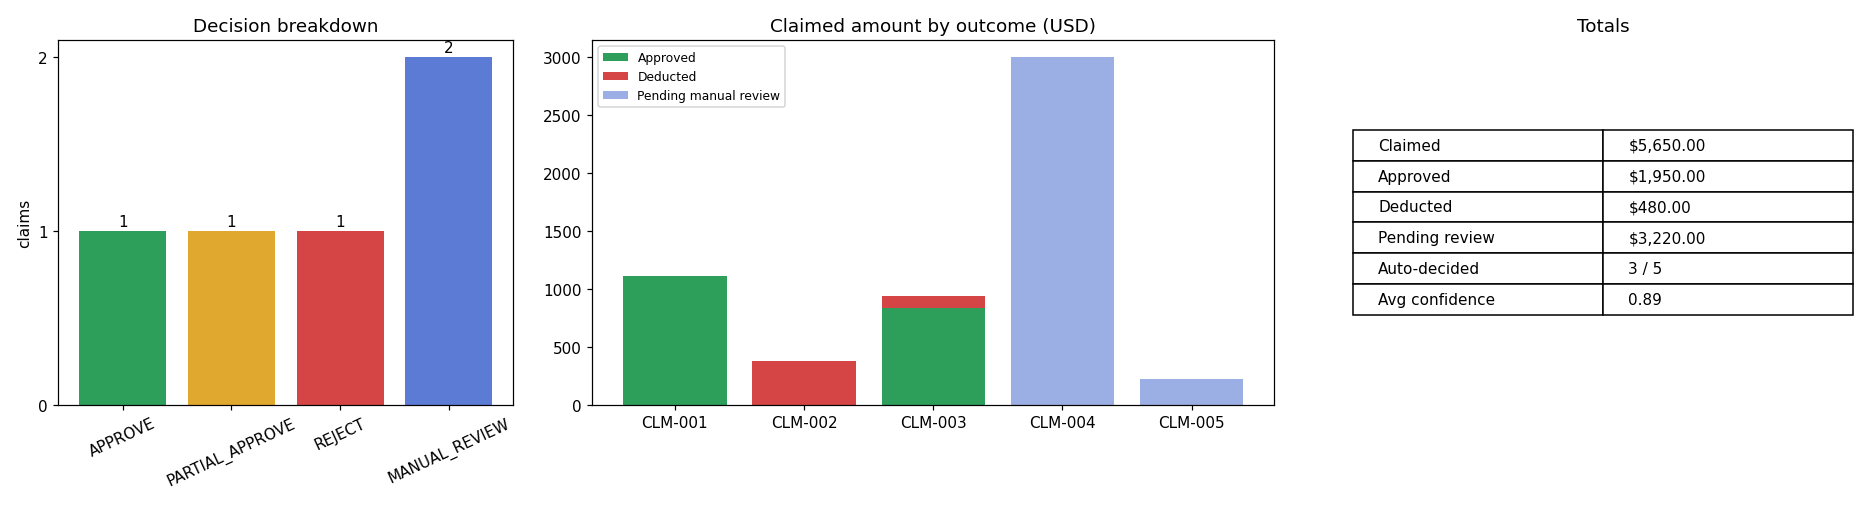

claim_id,decision,claimed,approved_amount,deducted_amount,pending,confidence
CLM-001,APPROVE,1110.0,1110.0,0.0,0.0,0.97
CLM-002,REJECT,380.0,0.0,380.0,0.0,0.96
CLM-003,PARTIAL_APPROVE,940.0,840.0,100.0,0.0,0.93
CLM-004,MANUAL_REVIEW,3000.0,0.0,0.0,3000.0,0.85
CLM-005,MANUAL_REVIEW,220.0,0.0,0.0,220.0,0.75


In [7]:
df = pd.DataFrame(RESULTS)
df["claimed"] = [claimed_total(CLAIMS_BY_ID[i]) for i in df.claim_id]
df["pending"] = df.apply(lambda r: r.claimed if r.decision == "MANUAL_REVIEW" else 0.0, axis=1)
colors = {"APPROVE": "#2e9e5b", "PARTIAL_APPROVE": "#e0a82e", "REJECT": "#d64545", "MANUAL_REVIEW": "#5b7bd5"}

fig, ax = plt.subplots(1, 3, figsize=(17, 4.6), gridspec_kw={"width_ratios": [1, 1.5, 1.1]})
counts = df.decision.value_counts().reindex(DECISIONS).fillna(0)
ax[0].bar(counts.index, counts.values, color=[colors[d] for d in counts.index])
ax[0].set_title("Decision breakdown"); ax[0].set_ylabel("claims"); ax[0].tick_params(axis="x", rotation=25)
ax[0].set_yticks(range(int(counts.max()) + 1))
for i, v in enumerate(counts.values): ax[0].text(i, v + 0.03, int(v), ha="center")

x = range(len(df))
ax[1].bar(x, df.approved_amount, label="Approved", color="#2e9e5b")
ax[1].bar(x, df.deducted_amount, bottom=df.approved_amount, label="Deducted", color="#d64545")
ax[1].bar(x, df.pending, bottom=df.approved_amount + df.deducted_amount, label="Pending manual review", color="#5b7bd5", alpha=.6)
ax[1].set_xticks(list(x)); ax[1].set_xticklabels(df.claim_id); ax[1].set_title("Claimed amount by outcome (USD)"); ax[1].legend(fontsize=8)

ax[2].axis("off"); ax[2].set_title("Totals")
tot = [["Claimed", f"${df.claimed.sum():,.2f}"], ["Approved", f"${df.approved_amount.sum():,.2f}"],
       ["Deducted", f"${df.deducted_amount.sum():,.2f}"], ["Pending review", f"${df.pending.sum():,.2f}"],
       ["Auto-decided", f"{(df.decision != 'MANUAL_REVIEW').sum()} / {len(df)}"], ["Avg confidence", f"{df.confidence.mean():.2f}"]]
t = ax[2].table(cellText=tot, loc="center", cellLoc="left"); t.scale(1, 1.8); t.auto_set_font_size(False); t.set_fontsize(10)
plt.tight_layout(); plt.savefig("UI SS_1.png", dpi=110); plt.show()
df[["claim_id", "decision", "claimed", "approved_amount", "deducted_amount", "pending", "confidence"]]

### Interactive claim viewer
Pick a claim to inspect the agent's audit trail (every tool call with inputs and outputs). Requires `ipywidgets`; without it the cell prints the trail for CLM-004 as a demo.

In [8]:
def show_audit(cid):
    a = AUDIT[cid]; r = next(x for x in RESULTS if x["claim_id"] == cid)
    print(f"{cid} -> {r['decision']}  (approved ${r['approved_amount']:,.2f}, deducted ${r['deducted_amount']:,.2f})")
    for n in a["notes"]: print("  note:", n)
    for step, t in enumerate(a["trail"], 1):
        out = json.dumps(t["output"])
        print(f"  {step}. {t['tool']}({json.dumps(t['input'])[:70]}) -> {out[:230]}{'...' if len(out) > 230 else ''}")

try:
    import ipywidgets as w
    from IPython.display import display, clear_output
    dd, out = w.Dropdown(options=[c["claim_id"] for c in CLAIMS], description="Claim:"), w.Output()
    def _on(_=None):
        with out: clear_output(); show_audit(dd.value)
    dd.observe(_on, "value"); display(dd, out); _on()
except ImportError:
    show_audit("CLM-004")

CLM-004 -> MANUAL_REVIEW  (approved $0.00, deducted $0.00)
  1. policy_lookup({"query": "airfare lodging receipt approval threshold timeliness submi) -> {"rules": [{"id": "POL-RCT-01", "title": "Receipt required above $25", "text": "Any single line item > $25 needs an attached itemized receipt. Airfare and lodging always need a receipt."}, {"id": "POL-TIME-01", "title": "Submissio...
  2. check_eligibility({"claim_id": "CLM-004"}) -> {"eligible": ["airfare", "lodging"], "ineligible": [], "unknown_category": [], "eligible_total": 3000.0, "ineligible_total": 0, "unknown_total": 0, "refs": ["POL-CAT-01"]}
  3. check_limits({"claim_id": "CLM-004"}) -> {"lines": [{"category": "airfare", "claimed": 2400.0, "qty": 1, "cap": null, "allowed": 2400.0, "deducted": 0.0}, {"category": "lodging", "claimed": 600.0, "qty": 3, "cap": 600, "allowed": 600.0, "deducted": 0.0}], "allowed_total"...
  4. check_receipts({"claim_id": "CLM-004"}) -> {"missing": [{"category": "lodging", "amount": 600.0, "doc": "

## Design Notes & Reasoning

**Approach.** The LLM is the *orchestrator* (chooses tools, reads results, writes the explanation); deterministic code is the *authority* on arithmetic and policy outcome. For a money-approval task a hallucinated deduction is worse than a slightly stiff explanation, so the model's verdict is checked against a rule engine and the LLM may only escalate to `MANUAL_REVIEW`, never relax a flagged claim.

**Results and why.**
- **CLM-001 -> APPROVE ($1,110).** Eligible, receipts present, lodging $180/night and meals $60/day are under caps, total in manager tier (POL-APR-02).
- **CLM-002 -> REJECT ($380 deducted).** Spa and minibar are both POL-CAT-02; nothing reimbursable.
- **CLM-003 -> PARTIAL_APPROVE ($840 approved, $100 deducted).** Lodging $250 x 2 nights vs $200 cap deducts $100 (POL-PD-02); meals $70/day is fine.
- **CLM-004 -> MANUAL_REVIEW.** Three independent triggers: business-class fare (POL-AIR-01, a pre-approval may exist), missing lodging receipt (POL-RCT-02), total $3,000 > $2,000 (POL-APR-03). Any one would suffice, all are listed so the reviewer sees everything at once.
- **CLM-005 -> MANUAL_REVIEW.** $220 meal with no receipt (POL-RCT-02), and a 4-person client dinner makes the $75/day per-diem ambiguous (per person or per claimant?). The policy does not say, so the agent does not guess.

**Assumptions**
- The expense date for the 30-day window is the trip end date (no per-item dates are provided). All five claims are well inside the window.
- Nights/days are read from the line description (`qty`). A cap is `qty x limit` applied to the line total (a day-by-day split is not available).
- For `MANUAL_REVIEW` the agent reports $0 approved / $0 deducted; the pending amount is in the explanation.
- Confidence is a heuristic (clean cases high, exceptions lower), not a calibrated probability.

**Trade-offs**
- *Lexical policy retrieval* instead of embeddings/vector DB: 12 rules fit in context; extra infrastructure would be over-engineering. With a full handbook I would switch to embeddings.
- *No agent framework*: a ~30-line tool loop on the raw API is easier to review and debug than LangChain/CrewAI for 6 tools.
- *Offline planner*: keeps the notebook reproducible without an API key. In that mode the LLM does not choose tools; the tool-calling loop (`run_llm`) is only exercised when a key is set and was not run in the saved outputs.

**Known gaps / next steps**
- Evaluate `run_llm` against the 5 claims over multiple runs and measure agreement with the rule engine.
- Per-item dates and per-day aggregation of meals/ground transport (caps are per day, not per line).
- Duplicate-claim detector, currency conversion, receipt OCR/metadata verification, and pre-approval lookup so business-class claims with approval can be cleared.
- Per-person meal policy clarification (CLM-005) from Finance, then encode it as a rule.
- Unit tests for each tool and a golden-set evaluation script; reviewer queue with reason codes.

## 7. Final structured results

In [9]:
print(json.dumps(RESULTS, indent=2))

[
  {
    "claim_id": "CLM-001",
    "decision": "APPROVE",
    "approved_amount": 1110.0,
    "deducted_amount": 0.0,
    "missing_docs": [],
    "policy_refs": [
      "POL-APR-02",
      "POL-CAT-01",
      "POL-RCT-01"
    ],
    "confidence": 0.97,
    "explanation": "All 4 items are eligible (POL-CAT-01), receipts are attached (POL-RCT-01) and amounts are within per-diem caps. Reimbursable total $1,110.00 is in the manager tier, approvable when compliant (POL-APR-02). Approved in full.",
    "tools_used": [
      "policy_lookup",
      "check_eligibility",
      "check_limits",
      "check_receipts",
      "check_timeliness",
      "check_threshold",
      "validate_output"
    ]
  },
  {
    "claim_id": "CLM-002",
    "decision": "REJECT",
    "approved_amount": 0.0,
    "deducted_amount": 380.0,
    "missing_docs": [],
    "policy_refs": [
      "POL-CAT-02"
    ],
    "confidence": 0.96,
    "explanation": "All claimed items (spa, minibar) are ineligible under POL-CAT-02, so 